# Baseline Model — Random Forest

Starting with a simple Random Forest to see how well the extracted features work. This gives me a baseline to compare against when I try other models later.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, accuracy_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder, label_binarize

from helpers import FEATURE_NAMES

sns.set_style("whitegrid")

FEAT_DIR = Path("../features")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

## 1. Load features

In [15]:
X = np.load(FEAT_DIR / "X_train.npy")
y = np.load(FEAT_DIR / "y_train.npy", allow_pickle=True)

print(f"X: {X.shape}, y: {y.shape}")
print(f"Unique species: {len(np.unique(y))}")

X: (35549, 60), y: (35549,)
Unique species: 206


## 2. Train/validation split

In [16]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# some species have only 1 sample — can't stratify those
# keep only species with at least 2 samples
counts = np.bincount(y_encoded)
valid_classes = np.where(counts >= 2)[0]
mask = np.isin(y_encoded, valid_classes)

print(f"Removed {(~mask).sum()} samples from {len(counts) - len(valid_classes)} species with < 2 samples")

X_filt = X[mask]
y_filt = y_encoded[mask]

X_train, X_val, y_train, y_val = train_test_split(
    X_filt, y_filt, test_size=0.2, random_state=42, stratify=y_filt
)

print(f"Train: {X_train.shape}, Val: {X_val.shape}")
print(f"Classes: {len(le.classes_)}")

Removed 4 samples from 4 species with < 2 samples
Train: (28436, 60), Val: (7109, 60)
Classes: 206


## 3. Train Random Forest

In [17]:
import time

start = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
train_time = time.time() - start

print(f"Training time: {train_time:.1f}s")

Training time: 8.3s


## 4. Evaluate on validation split

In [18]:
y_pred = rf.predict(X_val)
y_proba = rf.predict_proba(X_val)

acc = accuracy_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred, average='macro', zero_division=0)

# compute per-class ROC-AUC, skipping classes not in val set
model_classes = rf.classes_
per_class_auc = []
for i, cls in enumerate(model_classes):
    cls_mask = (y_val == cls)
    if cls_mask.sum() > 0 and cls_mask.sum() < len(y_val):
        auc_i = roc_auc_score((y_val == cls).astype(int), y_proba[:, i])
        per_class_auc.append(auc_i)
roc_auc = np.mean(per_class_auc)

print("=== Validation (train_audio held-out 20%) ===")
print(f"Accuracy:       {acc:.4f}")
print(f"Macro F1:       {f1:.4f}")
print(f"Macro ROC-AUC:  {roc_auc:.4f} (over {len(per_class_auc)} classes with samples in val)")

=== Validation (train_audio held-out 20%) ===
Accuracy:       0.2159
Macro F1:       0.1764
Macro ROC-AUC:  0.7438 (over 199 classes with samples in val)


The accuracy looks low at 21%, but with 202 classes, random guessing would only give about 0.5%. So the model is doing much better than chance.

The macro F1 is also low, mainly because rare species with very few validation samples pull the average down.

The ROC-AUC of 0.74 is more encouraging — it means the model usually gives the correct species a relatively high probability, even if it doesn't always rank it #1. ROC-AUC is computed only for classes that have at least one positive and one negative example in the validation set.

## 5. Evaluate on labeled soundscapes

The soundscape labels have multiple species per segment (e.g. `"22961;23158;24321"`), but my model only predicts one species. So I just check if the model's prediction is among the true species listed — it's a rough measure but gives an idea of how well things transfer to real-world audio.

In [19]:
X_sc = np.load(FEAT_DIR / "X_soundscape.npy")
y_sc = np.load(FEAT_DIR / "y_soundscape.npy", allow_pickle=True)

# predict on soundscapes
y_sc_pred = rf.predict(X_sc)
y_sc_pred_labels = le.inverse_transform(y_sc_pred)

# check if prediction is among the true species
hits = 0
for pred, true_str in zip(y_sc_pred_labels, y_sc):
    true_species = true_str.split(';')
    if pred in true_species:
        hits += 1

top1_acc = hits / len(y_sc)
print(f"=== Soundscape evaluation ===")
print(f"Segments: {len(y_sc)}")
print(f"Top-1 hit rate: {top1_acc:.4f} ({hits}/{len(y_sc)})")
print(f"(model's prediction is among the true species {top1_acc*100:.1f}% of the time)")

=== Soundscape evaluation ===
Segments: 1478
Top-1 hit rate: 0.0230 (34/1478)
(model's prediction is among the true species 2.3% of the time)


Only 2.3% — that's really low compared to the 21% on the validation set. But I expected this. The training audio is clean and close-up, while soundscapes have background noise, overlapping species, wind, etc. This is the domain shift problem.

A proper multi-label evaluation (predicting each species independently) might give better results, but for now this shows how much harder the real-world setting is.

## 6. Feature importance

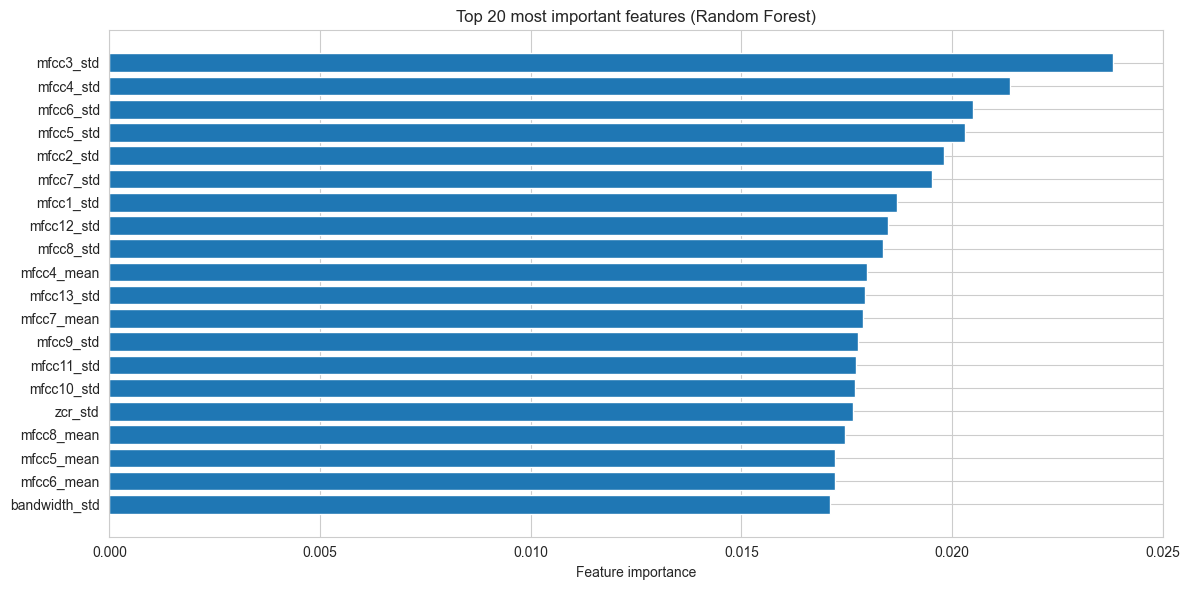

In [20]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1][:20]

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(range(20), importances[indices][::-1])
ax.set_yticks(range(20))
ax.set_yticklabels([FEATURE_NAMES[i] for i in indices][::-1])
ax.set_xlabel("Feature importance")
ax.set_title("Top 20 most important features (Random Forest)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance_baseline.png", dpi=150)
plt.show()

As expected, the MFCC features dominate. They capture the overall spectral shape of the audio, which makes sense — different species have different frequency patterns. The spectral and chroma features contribute less individually.

## 7. Save results

In [21]:
results = {
    "model": "RandomForest(100 trees, default)",
    "features": "SET_C (60 features, mean+std)",
    "val_accuracy": round(acc, 4),
    "val_macro_f1": round(f1, 4),
    "val_macro_roc_auc": round(roc_auc, 4),
    "soundscape_top1_hit_rate": round(top1_acc, 4),
    "train_time_seconds": round(train_time, 1),
    "n_train": len(X_train),
    "n_val": len(X_val),
    "n_classes": len(le.classes_),
}

with open(FIG_DIR / "baseline_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved baseline results:")
for k, v in results.items():
    print(f"  {k}: {v}")

Saved baseline results:
  model: RandomForest(100 trees, default)
  features: SET_C (60 features, mean+std)
  val_accuracy: 0.2159
  val_macro_f1: 0.1764
  val_macro_roc_auc: 0.7438
  soundscape_top1_hit_rate: 0.023
  train_time_seconds: 8.3
  n_train: 28436
  n_val: 7109
  n_classes: 206


## Summary

This Random Forest gives me a baseline to compare everything else against.

| Metric | Value |
|--------|-------|
| Validation accuracy | 21.6% |
| Validation macro F1 | 0.176 |
| Validation macro ROC-AUC | 0.744 |
| Soundscape top-1 hit rate | 2.3% |
| Training time | ~8s |

The features clearly contain useful signal (ROC-AUC well above 0.5), but there's a big gap when testing on real soundscapes. Next I'll try different feature sets and models to see if I can improve these numbers.